In [3]:

import zipfile
import os

# Extract the ZIP file
with zipfile.ZipFile("/content/hotel_bookings.csv.zip", "r") as zip_ref:
    zip_ref.extractall("/content/")

# Check which files are available
print(os.listdir("/content/"))


['.config', 'hotel_bookings.csv.zip', 'hotel_bookings.csv', 'sample_data']


In [4]:

import pandas as pd
import matplotlib.pyplot as plt

# Load the extracted CSV file
df = pd.read_csv("/content/hotel_bookings.csv")

# Display the first 5 rows
df.head()


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


In [5]:

print("Dataset Shape:", df.shape)
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])


Dataset Shape: (119390, 32)
Number of rows: 119390
Number of columns: 32



# 1. Structural Overview


In [6]:

# 1. Check the number of rows and columns
print("Dataset Shape:", df.shape)

# 2. Display column names
print("\nColumn Names:")
print(df.columns.tolist())

# 3. Display data types
print("\nColumn Data Types:")
print(df.dtypes)

# 4. Display memory usage and dataset information
print("\nDataset Information:")
df.info(memory_usage="deep")

# 5. Display the first 5 rows
print("\nFirst 5 Rows:")
display(df.head())

# 6. Display the last 5 rows
print("\nLast 5 Rows:")
display(df.tail())


Dataset Shape: (119390, 32)

Column Names:
['hotel', 'is_canceled', 'lead_time', 'arrival_date_year', 'arrival_date_month', 'arrival_date_week_number', 'arrival_date_day_of_month', 'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'children', 'babies', 'meal', 'country', 'market_segment', 'distribution_channel', 'is_repeated_guest', 'previous_cancellations', 'previous_bookings_not_canceled', 'reserved_room_type', 'assigned_room_type', 'booking_changes', 'deposit_type', 'agent', 'company', 'days_in_waiting_list', 'customer_type', 'adr', 'required_car_parking_spaces', 'total_of_special_requests', 'reservation_status', 'reservation_status_date']

Column Data Types:
hotel                              object
is_canceled                         int64
lead_time                           int64
arrival_date_year                   int64
arrival_date_month                 object
arrival_date_week_number            int64
arrival_date_day_of_month           int64
stays_in_weekend_nights 

,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03



Last 5 Rows:


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
119385,City Hotel,0,23,2017,August,35,30,2,5,2,...,No Deposit,394.0,NaN,0,Transient,96.14,0,0,Check-Out,2017-09-06
119386,City Hotel,0,102,2017,August,35,31,2,5,3,...,No Deposit,9.0,NaN,0,Transient,225.43,0,2,Check-Out,2017-09-07
119387,City Hotel,0,34,2017,August,35,31,2,5,2,...,No Deposit,9.0,NaN,0,Transient,157.71,0,4,Check-Out,2017-09-07
119388,City Hotel,0,109,2017,August,35,31,2,5,2,...,No Deposit,89.0,NaN,0,Transient,104.40,0,0,Check-Out,2017-09-07
119389,City Hotel,0,205,2017,August,35,29,2,7,2,...,No Deposit,9.0,NaN,0,Transient,151.20,0,2,Check-Out,2017-09-07


### Interpretation

The dataset contains 5 rows and 32 columns. It includes numerical and categorical variables related to hotel bookings. The data types and memory usage were examined using Pandas, and the first and last five records were displayed to understand the dataset structure.

2. Missing Value Analysis

In [7]:

# Count missing values in each column
missing_count = df.isnull().sum()

# Calculate missing percentage
missing_percent = (missing_count / len(df)) * 100

# Create a summary table
missing_summary = pd.DataFrame({
    "Missing Values": missing_count,
    "Missing Percentage": missing_percent.round(2)
})

# Display only columns with missing values
missing_summary = missing_summary[
    missing_summary["Missing Values"] > 0
].sort_values("Missing Percentage", ascending=False)

display(missing_summary)


,Missing Values,Missing Percentage
company,112593,94.31
agent,16340,13.69
country,488,0.41
children,4,0.00


### Interpretation

The company column has the highest percentage of missing values, at 94.31%, followed by the agent column at 13.69%. The country column has only 488 missing values, while the children column has just 4. These results show that missing data is concentrated mainly in the company column. The missing values should be considered carefully before deciding whether to fill or remove them.

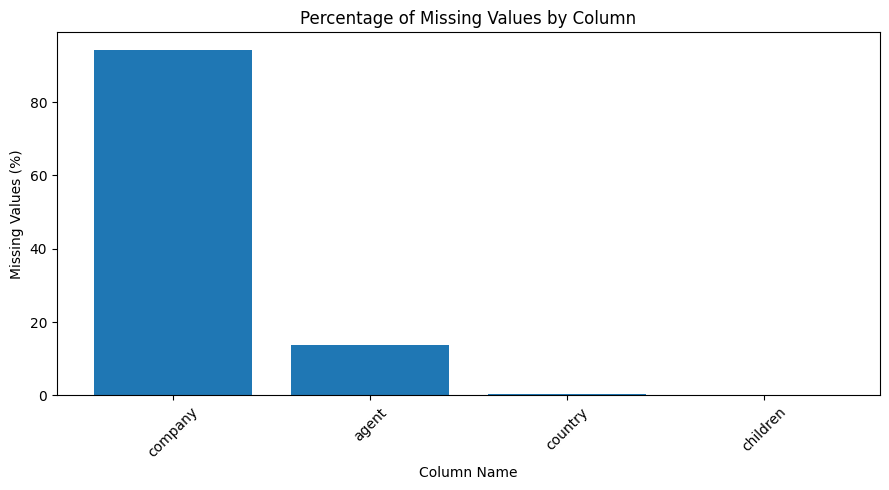

In [8]:

# Plot missing values as percentages
if not missing_summary.empty:
    plt.figure(figsize=(9, 5))

    plt.bar(
        missing_summary.index,
        missing_summary["Missing Percentage"]
    )

    plt.title("Percentage of Missing Values by Column")
    plt.xlabel("Column Name")
    plt.ylabel("Missing Values (%)")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()


Missing Value Visualization — Observation

The company bar has the more number of missing values as compared to others as shown in the above graph.

3. Summary Statistics

In [9]:

# Summary statistics for numerical columns
display(df.describe().T)

# Median of numerical columns
print("Median of Numerical Columns:")
display(df.select_dtypes(include="number").median())


,count,mean,std,min,25%,50%,75%,max
is_canceled,119390.0,0.370416,0.482918,0.00,0.00,0.000,1.0,1.0
lead_time,119390.0,104.011416,106.863097,0.00,18.00,69.000,160.0,737.0
arrival_date_year,119390.0,2016.156554,0.707476,2015.00,2016.00,2016.000,2017.0,2017.0
arrival_date_week_number,119390.0,27.165173,13.605138,1.00,16.00,28.000,38.0,53.0
arrival_date_day_of_month,119390.0,15.798241,8.780829,1.00,8.00,16.000,23.0,31.0
stays_in_weekend_nights,119390.0,0.927599,0.998613,0.00,0.00,1.000,2.0,19.0
stays_in_week_nights,119390.0,2.500302,1.908286,0.00,1.00,2.000,3.0,50.0
adults,119390.0,1.856403,0.579261,0.00,2.00,2.000,2.0,55.0
children,119386.0,0.103890,0.398561,0.00,0.00,0.000,0.0,10.0
babies,119390.0,0.007949,0.097436,0.00,0.00,0.000,0.0,10.0


Median of Numerical Columns:


,0
is_canceled,0.000
lead_time,69.000
arrival_date_year,2016.000
arrival_date_week_number,28.000
arrival_date_day_of_month,16.000
stays_in_weekend_nights,1.000
stays_in_week_nights,2.000
adults,2.000
children,0.000
babies,0.000


4. Categorical Data Analysis

In [10]:

# Select important categorical columns
categorical_columns = [
    "hotel",
    "meal",
    "customer_type",
    "reservation_status"
]

# Display the counts for each category
for column in categorical_columns:
    if column in df.columns:
        print("\nValue counts for:", column)
        display(df[column].value_counts(dropna=False))



Value counts for: hotel


,count
hotel,
City Hotel,79330
Resort Hotel,40060



Value counts for: meal


,count
meal,
BB,92310
HB,14463
SC,10650
Undefined,1169
FB,798



Value counts for: customer_type


,count
customer_type,
Transient,89613
Transient-Party,25124
Contract,4076
Group,577



Value counts for: reservation_status


,count
reservation_status,
Check-Out,75166
Canceled,43017
No-Show,1207


### Interpretation

The categorical analysis shows the distribution of hotel types, meal plans, customer types, and reservation statuses. The most frequent category in each column can be identified from the value counts, helping us understand the common patterns in hotel bookings.

5. Data Visualization

5.1 Hotel Booking Cancellation Status

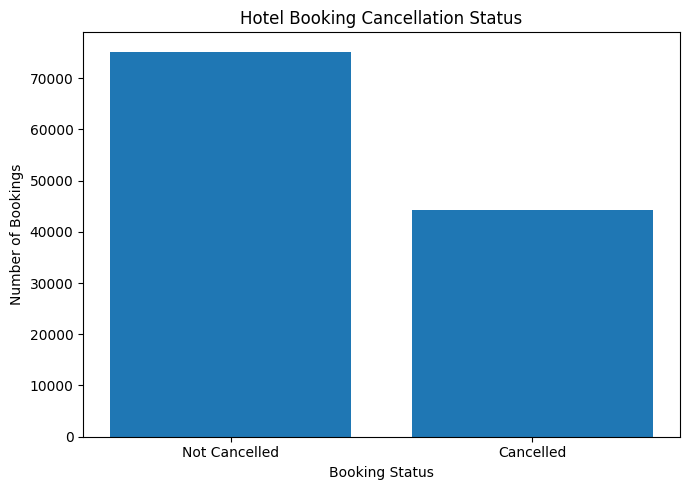

In [11]:

# Count cancelled and non-cancelled bookings
cancellation_counts = df["is_canceled"].map({
    0: "Not Cancelled",
    1: "Cancelled"
}).value_counts()

# Create bar chart
plt.figure(figsize=(7, 5))
plt.bar(cancellation_counts.index, cancellation_counts.values)

plt.title("Hotel Booking Cancellation Status")
plt.xlabel("Booking Status")
plt.ylabel("Number of Bookings")

plt.tight_layout()
plt.show()


### Interpretation

The chart shows that the number of NOT CANCELLED bookings is higher than the number of CANCELLED bookings.This indicates that most hotel reservations in the dataset were completed without cancellation.

5.2 Distribution of Booking Lead Time

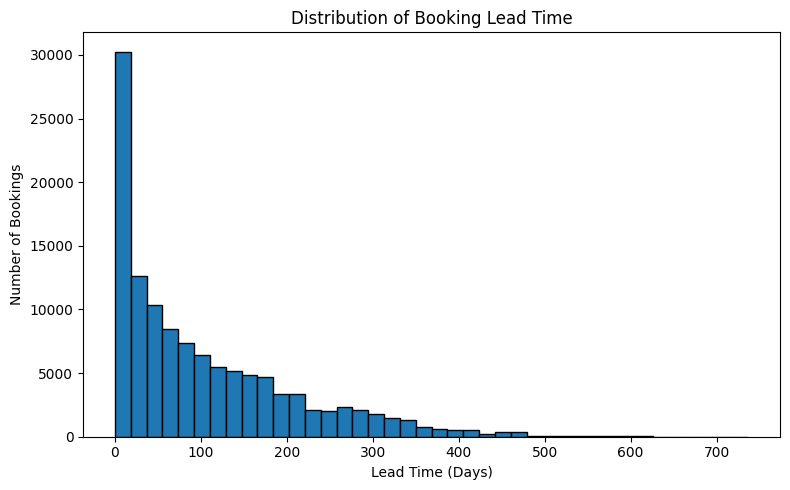

In [12]:

# Distribution of booking lead time
plt.figure(figsize=(8, 5))

plt.hist(df["lead_time"].dropna(), bins=40, edgecolor="black")

plt.title("Distribution of Booking Lead Time")
plt.xlabel("Lead Time (Days)")
plt.ylabel("Number of Bookings")

plt.tight_layout()
plt.show()


### Interpretation

The histogram shows that bookings are more concentrated on the left side of the graph, indicating that many bookings have shorter lead times. The distribution extends toward longer lead times, suggesting that some customers book their hotels well in advance.

5.3 Average Daily Rate by Hotel Type

<Figure size 900x600 with 0 Axes>

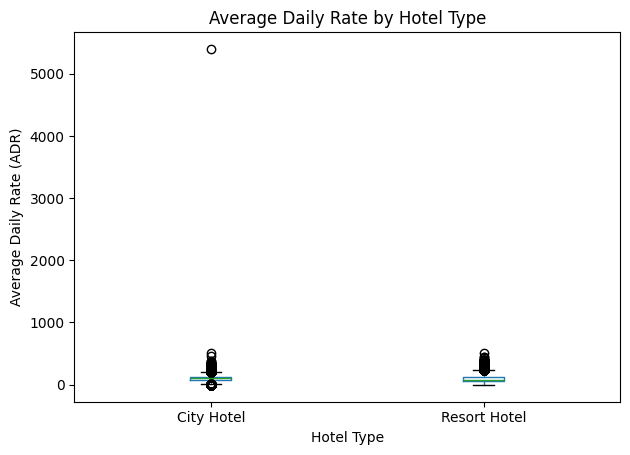

In [14]:

plt.figure(figsize=(9, 6))

df.boxplot(
    column="adr",
    by="hotel",
    grid=False
)

plt.title("Average Daily Rate by Hotel Type")
plt.suptitle("")
plt.xlabel("Hotel Type")
plt.ylabel("Average Daily Rate (ADR)")
plt.tight_layout()
plt.show()


In [15]:

# Compare median and mean daily rates by hotel type
display(
    df.groupby("hotel")["adr"]
    .agg(["median", "mean"])
    .round(2)
)


,median,mean
hotel,,
City Hotel,99.9,105.30
Resort Hotel,75.0,94.95


### Interpretation

The boxplot compares average daily rates between City Hotel and Resort Hotel. City Hotel has a higher median daily rate than Resort Hotel, indicating that the typical daily room rate is higher for City Hotel in this dataset.

5.4 Booking Cancellation Rate by Hotel Type

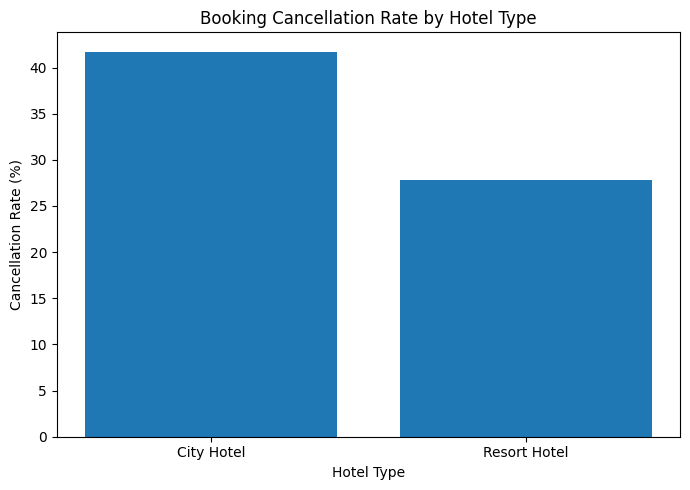

,is_canceled
hotel,
City Hotel,41.73
Resort Hotel,27.76


In [16]:

# Calculate cancellation percentage for each hotel type
cancellation_by_hotel = (
    df.groupby("hotel")["is_canceled"].mean() * 100
)

# Create bar chart
plt.figure(figsize=(7, 5))

plt.bar(
    cancellation_by_hotel.index,
    cancellation_by_hotel.values
)

plt.title("Booking Cancellation Rate by Hotel Type")
plt.xlabel("Hotel Type")
plt.ylabel("Cancellation Rate (%)")

plt.tight_layout()
plt.show()

# Display exact cancellation percentages
display(cancellation_by_hotel.round(2))


Observation: The chart shows that City Hotel has a higher booking cancellation rate than Resort Hotel. This indicates that reservations at City Hotel are cancelled more frequently as a percentage of total bookings. The hotel management could investigate the reasons for these cancellations and consider strategies to reduce them.

5.5 Number of Bookings by Arrival Month

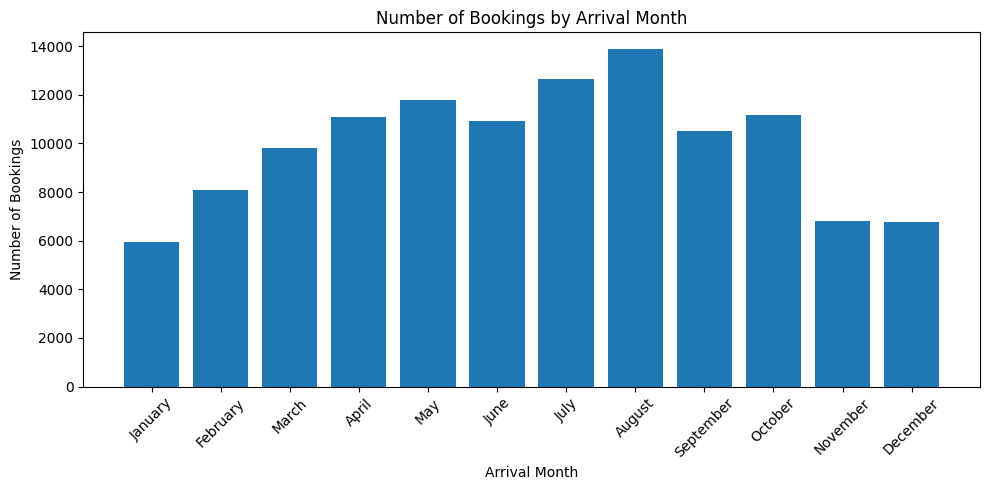

In [17]:
# Count bookings for each arrival month
month_order = [
    "January", "February", "March", "April",
    "May", "June", "July", "August",
    "September", "October", "November", "December"
]

monthly_bookings = df["arrival_date_month"].value_counts()
monthly_bookings = monthly_bookings.reindex(month_order)

# Create bar chart
plt.figure(figsize=(10, 5))
plt.bar(monthly_bookings.index, monthly_bookings.values)
plt.title("Number of Bookings by Arrival Month")
plt.xlabel("Arrival Month")
plt.ylabel("Number of Bookings")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Observation: The chart shows that August has the highest number of hotel bookings, while January has the lowest.

5.6 Correlation Heatmap of Numerical Features

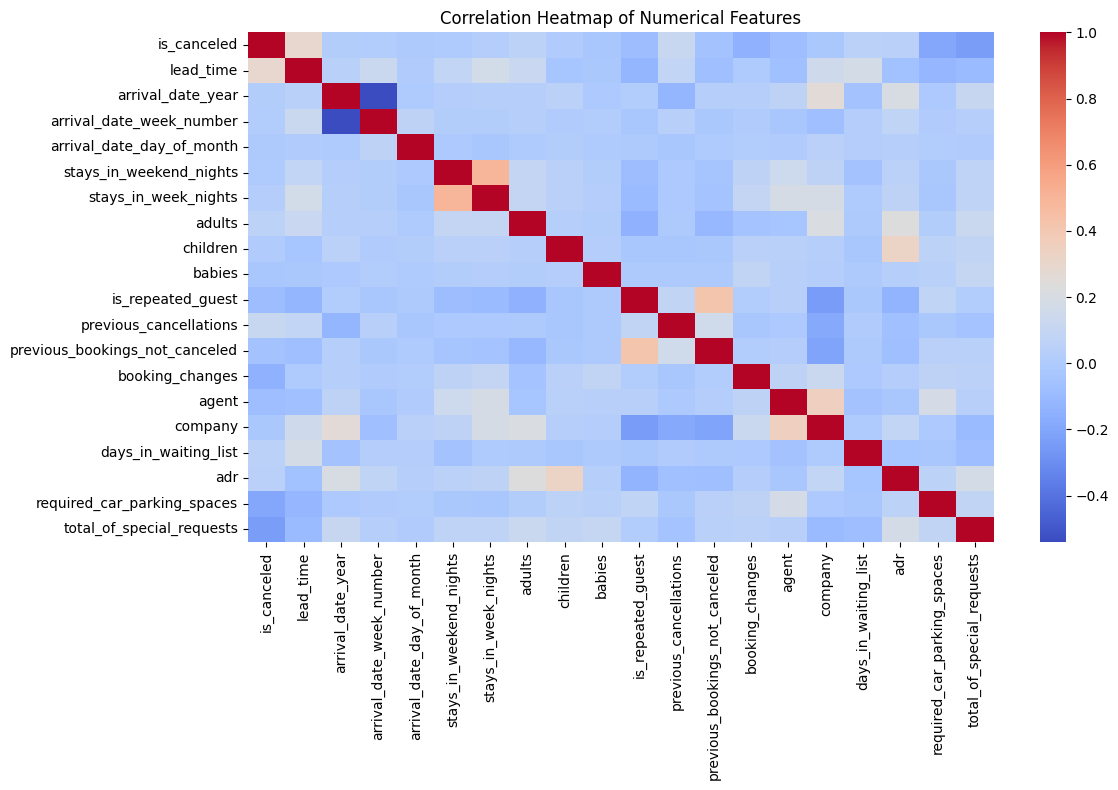

In [18]:
import seaborn as sns

# Select numerical columns
numerical_data = df.select_dtypes(include="number")

# Calculate correlations
correlation = numerical_data.corr()

# Plot heatmap
plt.figure(figsize=(12, 8))
sns.heatmap(correlation, cmap="coolwarm", annot=False)
plt.title("Correlation Heatmap of Numerical Features")
plt.tight_layout()
plt.show()

Observation: The correlation heatmap shows positive and negative relationships among numerical features in the hotel booking dataset. Red shades represent positive correlations, while blue shades represent negative correlations.

6. Key Findings

Booking status: Non-cancelled bookings are higher than cancelled bookings.



Lead time: Many bookings have shorter lead times, with fewer bookings spread across longer lead times.



Daily room rates: City Hotel has a higher median Average Daily Rate (ADR) than Resort Hotel.



Cancellation rate: City Hotel has a higher cancellation rate than Resort Hotel.



Monthly bookings: August has the highest number of bookings, while January has the lowest.



Correlation analysis: The heatmap helps identify positive and negative relationships between numerical features.

7. Conclusion

In this project, Exploratory Data Analysis (EDA) was performed on the Hotel Booking Demand dataset using Python, Pandas, Matplotlib, and Seaborn. The analysis included examining the dataset structure, identifying missing values, calculating summary statistics, and analysing categorical and numerical features.

Visualizations were created to understand booking cancellation status, lead time distribution, average daily rates, cancellation rates by hotel type, monthly booking patterns, and correlations between numerical features.

The analysis revealed that non-cancelled bookings were more common, City Hotel had a higher median daily rate and cancellation rate than Resort Hotel, and August recorded the highest number of bookings while January recorded the lowest. Overall, this project demonstrates how data analysis and visualization can help identify booking patterns and support better hotel business decisions.